# Clase 16: Profiling, Green AI y Cierre del Curso

**Machine Learning (RIA-805) ? Bloque 3 ? Formulaci?n de Proyectos y Emprendimiento Sostenible**

**Docente:** [tu nombre]  
**Fecha:** Semana 5 (?ltima clase)

**Objetivo:** Medir el consumo de recursos del modelo (latencia, RAM, CPU, tama?o), estimar su huella de carbono y comparar el modelo original con ONNX, cerrando el curso con un an?lisis de sostenibilidad.

**Conexi?n con la pr?ctica:** En P3-6 a P3-9 har?n el profiling y el an?lisis de Green AI de su proyecto. Hoy ver?n exactamente c?mo se hace.

## Repaso del Bloque 3

| Actividad | Tema | Pregunta gu?a |
|---|---|---|
| AA 3.2 | Relevancia y sostenibilidad | ?Resuelve un problema pertinente y responsable? |
| CD 15 | MLOps, Docker y FastAPI | ?C?mo se empaqueta y sirve el modelo? |
| CD 16 | Profiling y Green AI | ?Qu? recursos consume y c?mo reducir su impacto? |

**Hoy cerramos el bloque y el curso.** Conectaremos la decisi?n de desplegar un modelo con mediciones observables y estimaciones transparentes.

## Profiling: medir el rendimiento real

El **profiling** consiste en medir c?mo se comporta un sistema mientras trabaja: cu?nto tarda y qu? recursos utiliza. Medir permite localizar cuellos de botella y comparar implementaciones con el mismo equipo, datos y condiciones. Una estimaci?n basada en supuestos no es una medici?n directa.

| M?trica | Qu? describe | Herramientas posibles |
|---|---|---|
| Latencia | Tiempo para responder una solicitud | `time.perf_counter_ns`, `timeit` |
| Throughput | Solicitudes procesadas por unidad de tiempo | pruebas de carga, `timeit` |
| RAM | Memoria residente del proceso | `psutil`, monitor del sistema operativo |
| CPU | Tiempo de CPU utilizado por el proceso | `psutil`, profiler del sistema |
| GPU | Uso de acelerador durante el c?lculo | NVIDIA `nvidia-smi`, herramientas del proveedor |
| Tama?o del modelo | Espacio del artefacto almacenado | `os.path.getsize` |
| Energ?a | Potencia integrada durante un intervalo | medidor de energ?a, RAPL, herramientas del proveedor |

En este laboratorio no disponemos de GPU ni de un medidor de energ?a. La huella de carbono se **estimar?** a partir de latencia y potencia supuesta.

## Latencia: promedio, p95 y p99

La **latencia** es el tiempo que transcurre desde que se solicita una predicci?n hasta que est? disponible. El promedio resume el tiempo t?pico, pero puede ocultar solicitudes lentas. El percentil 95 (p95) indica que aproximadamente el 95 % de las observaciones termin? en ese tiempo o menos; p99 hace lo mismo para el 99 %.

Por ejemplo, **promedio 2 ms y p99 50 ms** significa que la solicitud t?pica tarda alrededor de 2 ms, pero el 1 % m?s lento tarda aproximadamente 50 ms o m?s. **La p99 es cr?tica en producci?n** cuando se deben cumplir acuerdos de servicio y evitar respuestas lentas.

Los resultados dependen del hardware, calentamiento del proceso, carga concurrente, tama?o de lote y n?mero de repeticiones. Aqu? mediremos una fila por llamada y haremos un calentamiento previo.

## RAM y CPU

**RAM** es la memoria principal ocupada por un proceso mientras ejecuta. Con `psutil`, `Process.memory_info().rss` observa su memoria residente. **CPU** representa tiempo de ejecuci?n en el procesador; `psutil` permite comparar el tiempo de CPU consumido con el tiempo transcurrido.

> RAM alta = servidor m?s caro. CPU alta = cuello de botella.

El RSS medido dentro de un kernel incluye Python, librer?as, datos y todo lo cargado en ese proceso. No identifica qu? bytes pertenecen exclusivamente a un modelo. El porcentaje de CPU puede superar 100 % cuando el proceso utiliza varios n?cleos; runtimes como ONNX pueden crear hilos de trabajo. Por eso la CPU de una prueba breve es indicativa, no una comparaci?n aislada del hardware.

## Tama?o del modelo

El tama?o en disco corresponde al artefacto que se almacena o transfiere. **Modelos grandes = m?s tiempo de carga, m?s RAM, m?s transferencia.** La comparaci?n es justa solo si se consideran componentes equivalentes: si el modelo original incluye un escalador, la exportaci?n debe incluirlo tambi?n. El tama?o del archivo no es lo mismo que la memoria ocupada al predecir.

In [1]:
# Importaciones centrales para datos, medici?n, visualizaci?n y persistencia.
import copy
import json
import os
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

# Las dependencias opcionales no bloquean la comparaci?n con scikit-learn.
try:
    import psutil
    PSUTIL_AVAILABLE = True
except ImportError as error:
    psutil = None
    PSUTIL_AVAILABLE = False
    print(f"ADVERTENCIA: psutil no est? disponible; RAM/CPU se omitir?n ({error}).")

try:
    import onnxruntime as ort
    ONNX_RUNTIME_AVAILABLE = True
except ImportError as error:
    ort = None
    ONNX_RUNTIME_AVAILABLE = False
    print(f"ADVERTENCIA: onnxruntime no est? disponible; no se medir? ONNX ({error}).")

try:
    from skl2onnx import convert_sklearn
    from skl2onnx.common.data_types import FloatTensorType
    SKL2ONNX_AVAILABLE = True
except ImportError as error:
    convert_sklearn = None
    FloatTensorType = None
    SKL2ONNX_AVAILABLE = False
    print(f"ADVERTENCIA: skl2onnx no est? disponible; no se exportar? ONNX ({error}).")

# Los gr?ficos aparecen en el notebook; se silencian warnings conocidos de la pr?ctica.
%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
warnings.filterwarnings("ignore")

# Localizamos el repositorio tanto si Jupyter inici? en la ra?z como en notebooks/.
PROJECT_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "data" / "processed" / "crop.parquet").is_file()
     and (parent / "models").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se encontr? la ra?z del proyecto con data/processed/crop.parquet y models/."
    )

REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Ra?z del proyecto:", PROJECT_ROOT)

Ra?z del proyecto: C:\Users\lenovo\OneDrive\UCACUE\MACHIENE LEARNING\GITHUB PROYECTOS\ml-demo1-profesor


## Cargar el modelo y los datos del Bloque 2

Usaremos el modelo final del Bloque 2 y el conjunto procesado de cultivos. La tarea del modelo `rf_final_b2.pkl` es **binaria** (`rice` / `no rice`), mientras que `random_forest.pkl` es la referencia hist?rica multiclase. Respetaremos el preprocesamiento ajustado durante el entrenamiento cuando el modelo binario lo requiera.

La partici?n de prueba se usa ?nicamente para alimentar predicciones repetidas de la medici?n. No reentrenaremos ni usaremos estos tiempos como una nueva evaluaci?n de calidad.

In [2]:
# Elegimos el clasificador indicado y comprobamos que los artefactos requeridos existan.
FINAL_MODEL_PATH = PROJECT_ROOT / "models" / "rf_final_b2.pkl"
MULTICLASS_MODEL_PATH = PROJECT_ROOT / "models" / "random_forest.pkl"
BUNDLE_PATH = PROJECT_ROOT / "models" / "rf_final_b2_pipeline.pkl"
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "crop.parquet"

if FINAL_MODEL_PATH.is_file():
    MODEL_PATH = FINAL_MODEL_PATH
    modelo_original = joblib.load(MODEL_PATH)
    modelo_nombre = "Original B2"
    # El RF B2 se entren? con RobustScaler; recuperamos el escalador ya ajustado.
    if BUNDLE_PATH.is_file():
        bundle = joblib.load(BUNDLE_PATH)
        if not isinstance(bundle, Pipeline) or "scaler" not in bundle.named_steps:
            raise TypeError("El bundle B2 debe ser un Pipeline con el escalador ajustado.")
        if not np.array_equal(bundle.classes_, modelo_original.classes_):
            raise ValueError("El RF independiente y el bundle B2 tienen clases distintas.")
        modelo_serving = Pipeline([
            ("scaler", copy.deepcopy(bundle.named_steps["scaler"])),
            ("classifier", modelo_original),
        ])
        ORIGINAL_ARTIFACT_PATH = BUNDLE_PATH
    else:
        raise FileNotFoundError(
            "rf_final_b2.pkl necesita el preprocesamiento ajustado de "
            "rf_final_b2_pipeline.pkl para una inferencia correcta."
        )
else:
    MODEL_PATH = MULTICLASS_MODEL_PATH
    if not MODEL_PATH.is_file():
        raise FileNotFoundError(
            "No se encontr? models/rf_final_b2.pkl ni models/random_forest.pkl."
        )
    modelo_original = joblib.load(MODEL_PATH)
    modelo_serving = modelo_original
    ORIGINAL_ARTIFACT_PATH = MODEL_PATH
    modelo_nombre = "Original multiclase"

# Verificamos las siete variables y el archivo procesado antes de medir.
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
if getattr(modelo_serving, "n_features_in_", len(FEATURES)) != len(FEATURES):
    raise ValueError("El modelo cargado no acepta las siete variables del dataset.")
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Falta el dataset procesado: {DATA_PATH}")

crop_data = pd.read_parquet(DATA_PATH)
missing_columns = set(FEATURES + ["label"]) - set(crop_data.columns)
if missing_columns:
    raise ValueError(f"Faltan columnas en crop.parquet: {sorted(missing_columns)}")
X = crop_data[FEATURES].copy()
y = crop_data["label"].copy()
_, X_test, _, _ = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y,
)

print("Modelo seleccionado:", MODEL_PATH.relative_to(PROJECT_ROOT))
print("Artefacto original medido:", ORIGINAL_ARTIFACT_PATH.relative_to(PROJECT_ROOT))
print("Modo/clases:", len(modelo_serving.classes_), list(modelo_serving.classes_))
print("Datos completos:", X.shape, "| prueba para profiling:", X_test.shape)

Modelo seleccionado: models\rf_final_b2.pkl
Artefacto original medido: models\rf_final_b2_pipeline.pkl
Modo/clases: 2 [np.int64(0), np.int64(1)]
Datos completos: (2200, 7) | prueba para profiling: (440, 7)


## Medir latencia del modelo original

Mediremos llamadas individuales de predicci?n sobre filas del conjunto de prueba. Descartamos una llamada inicial para que el primer acceso/importaci?n no domine la medici?n. Los percentiles resumen las repeticiones de esta sesi?n; no son una garant?a del tiempo de respuesta en producci?n.

In [3]:
def medir_latencia(predict_fn, X, n=100):
    """Mide latencia por fila y devuelve promedio, p95 y p99 en milisegundos."""
    if len(X) == 0:
        raise ValueError("Se requiere al menos una fila para medir latencia.")
    if n < 1:
        raise ValueError("n debe ser al menos 1.")

    # Calentamos el predictor y limitamos repeticiones al tama?o de la muestra.
    predict_fn(X.iloc[[0]])
    repeticiones = min(int(n), len(X))
    tiempos_ms = []
    for indice in range(repeticiones):
        fila = X.iloc[[indice]]
        inicio = time.perf_counter_ns()
        predict_fn(fila)
        tiempos_ms.append((time.perf_counter_ns() - inicio) / 1_000_000)

    return {
        "promedio": float(np.mean(tiempos_ms)),
        "p95": float(np.percentile(tiempos_ms, 95)),
        "p99": float(np.percentile(tiempos_ms, 99)),
    }


# Usamos el mismo conjunto y protocolo para las comparaciones posteriores.
latencia_original = medir_latencia(modelo_serving.predict, X_test, n=100)
print("Latencia original por predicci?n (ms):", latencia_original)

Latencia original por predicci?n (ms): {'promedio': 75.42195099999999, 'p95': 101.23916499999997, 'p99': 118.67453600000002}


## Medir RAM y tama?o del modelo original

Registraremos el RSS del proceso del kernel y el tama?o del artefacto en disco. Si el preprocesamiento est? separado del clasificador, usamos el bundle serializado completo para que la comparaci?n con el ONNX sea equivalente. El RSS del kernel es una instant?nea aproximada, no memoria atribuible exclusivamente al modelo.

In [4]:
def medir_ram():
    """Devuelve el RSS actual del proceso en MB, o NaN si psutil no est? instalado."""
    if not PSUTIL_AVAILABLE:
        return float("nan")
    proceso = psutil.Process(os.getpid())
    return float(proceso.memory_info().rss / (1024 ** 2))


def medir_tamano(path):
    """Devuelve en MB el tama?o de un archivo existente."""
    ruta = Path(path)
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el artefacto que se quiere medir: {ruta}")
    return float(os.path.getsize(ruta) / (1024 ** 2))


def medir_cpu(predict_fn, X, n=100):
    """Estima el porcentaje de CPU del proceso durante n predicciones individuales."""
    if not PSUTIL_AVAILABLE or len(X) == 0 or n < 1:
        return float("nan")
    proceso = psutil.Process(os.getpid())
    # Evitamos contar la llamada de inicializaci?n de cpu_times en la ventana.
    proceso.cpu_times()
    repeticiones = min(int(n), len(X))
    cpu_inicio = proceso.cpu_times()
    pared_inicio = time.perf_counter()
    for indice in range(repeticiones):
        predict_fn(X.iloc[[indice]])
    pared_segundos = time.perf_counter() - pared_inicio
    cpu_fin = proceso.cpu_times()
    cpu_segundos = (cpu_fin.user - cpu_inicio.user) + (cpu_fin.system - cpu_inicio.system)
    return float(100 * cpu_segundos / pared_segundos) if pared_segundos > 0 else float("nan")


ram_original = medir_ram()
tamano_original = medir_tamano(ORIGINAL_ARTIFACT_PATH)
cpu_original = medir_cpu(modelo_serving.predict, X_test, n=100)
print(f"RSS del proceso con el modelo original: {ram_original:.2f} MB")
print(f"Tama?o del artefacto original: {tamano_original:.4f} MB")
print(f"CPU aproximada durante la prueba: {cpu_original:.2f}%")

RSS del proceso con el modelo original: 264.68 MB
Tama?o del artefacto original: 0.5535 MB
CPU aproximada durante la prueba: 99.92%


## Exportar a ONNX y comparar

ONNX puede facilitar la interoperabilidad y ofrecer un runtime de inferencia distinto, pero la conversi?n debe preservar el orden y tipo de las siete variables, el escalador del Bloque 2 y las clases. ONNX y su exportador son opcionales: si ya existe `models/modelo.onnx`, no lo sobrescribiremos; la clase guardar? su propia exportaci?n con otro nombre.

In [5]:
# Se conserva cualquier modelo.onnx que ya exista en el repositorio.
ONNX_PATH = PROJECT_ROOT / "models" / "modelo.onnx"
if ONNX_PATH.exists():
    ONNX_PATH = PROJECT_ROOT / "models" / "modelo_clase16.onnx"
if ONNX_PATH.exists():
    ONNX_PATH = PROJECT_ROOT / "models" / f"modelo_clase16_{time.strftime('%Y%m%d_%H%M%S')}.onnx"

onnx_available = False
onnx_session = None
onnx_error = None

if not SKL2ONNX_AVAILABLE:
    print("ADVERTENCIA: se omite la exportaci?n; instala skl2onnx para habilitarla.")
else:
    try:
        # Exportamos el pipeline completo para incluir el preprocesamiento ajustado.
        classifier = (
            modelo_serving.named_steps["classifier"]
            if isinstance(modelo_serving, Pipeline)
            else modelo_serving
        )
        onnx_model = convert_sklearn(
            modelo_serving,
            initial_types=[("input", FloatTensorType([None, len(FEATURES)]))],
            options={id(classifier): {"zipmap": False}},
            target_opset=17,
        )
        try:
            import onnx
            onnx.checker.check_model(onnx_model)
        except ImportError:
            print("ADVERTENCIA: no est? instalado onnx; se omite la comprobaci?n formal del grafo.")

        ONNX_PATH.write_bytes(onnx_model.SerializeToString())
        onnx_available = True
        print("Modelo ONNX guardado:", ONNX_PATH.relative_to(PROJECT_ROOT))
        print(f"Tama?o ONNX: {medir_tamano(ONNX_PATH):.4f} MB")
    except (ImportError, ValueError, TypeError, RuntimeError) as error:
        onnx_error = str(error)
        print(f"ADVERTENCIA: no se pudo convertir a ONNX; se contin?a con scikit-learn ({error}).")

Modelo ONNX guardado: models\modelo_clase16.onnx
Tama?o ONNX: 0.2024 MB


In [6]:
# Ejecutamos la misma entrada float32 en ONNX Runtime y revisamos concordancia.
latencia_onnx = {"promedio": np.nan, "p95": np.nan, "p99": np.nan}
ram_onnx = float("nan")
tamano_onnx = float("nan")
cpu_onnx = float("nan")

if onnx_available and ONNX_RUNTIME_AVAILABLE:
    try:
        onnx_session = ort.InferenceSession(
            str(ONNX_PATH), providers=["CPUExecutionProvider"],
        )
        onnx_input = onnx_session.get_inputs()[0]
        if len(onnx_input.shape) != 2 or onnx_input.shape[1] != len(FEATURES):
            raise ValueError(f"ONNX espera forma {onnx_input.shape}, no siete variables.")
        onnx_input_name = onnx_input.name

        def predecir_onnx(filas):
            """Predice etiquetas para filas con el artefacto ONNX CPU."""
            valores = filas[FEATURES].to_numpy(dtype=np.float32)
            salidas = onnx_session.run(None, {onnx_input_name: valores})
            return np.asarray(salidas[0]).reshape(-1)

        latencia_onnx = medir_latencia(predecir_onnx, X_test, n=100)
        ram_onnx = medir_ram()
        tamano_onnx = medir_tamano(ONNX_PATH)
        cpu_onnx = medir_cpu(predecir_onnx, X_test, n=100)
        print("Latencia ONNX por predicci?n (ms):", latencia_onnx)
        print(f"RSS del proceso con ONNX Runtime: {ram_onnx:.2f} MB")
        print(f"CPU aproximada durante la prueba: {cpu_onnx:.2f}%")

        # Las probabilidades pueden variar por precisi?n float32 y umbrales de ?rboles.
        filas_comparacion = X_test.iloc[:min(100, len(X_test))]
        salidas = onnx_session.run(
            None,
            {onnx_input_name: filas_comparacion.to_numpy(dtype=np.float32)},
        )
        pred_original = np.asarray(modelo_serving.predict(filas_comparacion)).reshape(-1)
        pred_convertido = np.asarray(salidas[0]).reshape(-1)
        etiquetas_coinciden = np.array_equal(pred_original.astype(str), pred_convertido.astype(str))
        probabilidades_originales = np.asarray(modelo_serving.predict_proba(filas_comparacion))
        salida_probabilidades = salidas[1]
        if isinstance(salida_probabilidades, list) and salida_probabilidades and isinstance(salida_probabilidades[0], dict):
            probabilidades_onnx = np.asarray([
                [fila.get(clase, fila.get(str(clase))) for clase in modelo_serving.classes_]
                for fila in salida_probabilidades
            ], dtype=float)
        else:
            probabilidades_onnx = np.asarray(salida_probabilidades, dtype=float)
        diferencia_probabilidad = float(np.max(np.abs(probabilidades_originales - probabilidades_onnx)))
        print(f"Etiquetas coincidentes en {len(filas_comparacion)} filas: {etiquetas_coinciden}")
        print(f"Diferencia m?xima de probabilidades: {diferencia_probabilidad:.8g}")
    except (ImportError, ValueError, RuntimeError, IndexError) as error:
        onnx_error = str(error)
        onnx_available = False
        print(f"ADVERTENCIA: no se pudo ejecutar/comparar ONNX ({error}).")
elif onnx_available:
    print("ADVERTENCIA: el export fue creado, pero falta onnxruntime; se omiten sus mediciones.")
else:
    print("ONNX no est? disponible; se omiten ejecuci?n y comparaci?n.")

Latencia ONNX por predicci?n (ms): {'promedio': 1.4182180000000002, 'p95': 2.199475, 'p99': 3.025377000000006}
RSS del proceso con ONNX Runtime: 274.59 MB
CPU aproximada durante la prueba: 397.58%


Etiquetas coincidentes en 100 filas: True
Diferencia m?xima de probabilidades: 6.5565109e-07


## Tabla comparativa: interpretar con cuidado

Comparamos latencia por fila, tama?o del artefacto desplegable y recursos observados. El RSS reportado es el del proceso Python: el modelo sklearn y la sesi?n ONNX comparten este kernel, por lo que la cifra ONNX incluye tambi?n los recursos que ya estaban cargados. **No se debe afirmar que ONNX ahorra RAM bas?ndose en esta instant?nea compartida**; para una comparaci?n aislada habr?a que medir ambos runtimes en procesos separados. Las cifras de esta m?quina tampoco predicen el rendimiento de otro hardware.

In [7]:
# Los valores ONNX no medidos quedan como NaN; no se inventan resultados.
comparacion = pd.DataFrame([
    {
        "modelo": modelo_nombre,
        "disponible": True,
        "latencia_promedio_ms": latencia_original["promedio"],
        "latencia_p95_ms": latencia_original["p95"],
        "latencia_p99_ms": latencia_original["p99"],
        "tamano_MB": tamano_original,
        "ram_MB": ram_original,
        "cpu_promedio_pct": cpu_original,
    },
    {
        "modelo": "ONNX",
        "disponible": bool(onnx_available and ONNX_RUNTIME_AVAILABLE),
        "latencia_promedio_ms": latencia_onnx["promedio"],
        "latencia_p95_ms": latencia_onnx["p95"],
        "latencia_p99_ms": latencia_onnx["p99"],
        "tamano_MB": tamano_onnx,
        "ram_MB": ram_onnx,
        "cpu_promedio_pct": cpu_onnx,
    },
])
comparacion_path = REPORTS_DIR / "profiling_comparativo.csv"
comparacion.to_csv(comparacion_path, index=False)
display(comparacion.round(4))
print("Reporte guardado:", comparacion_path.relative_to(PROJECT_ROOT))

,modelo,disponible,latencia_promedio_ms,latencia_p95_ms,latencia_p99_ms,tamano_MB,ram_MB,cpu_promedio_pct
0,Original B2,True,75.4220,101.2392,118.6745,0.5535,264.6758,99.9205
1,ONNX,True,1.4182,2.1995,3.0254,0.2024,274.5898,397.5790


Reporte guardado: reports\profiling_comparativo.csv


## Gr?fico comparativo

Los paneles muestran latencia promedio y tama?o de los artefactos para las implementaciones medidas. La escala de cada panel se ajusta a su unidad; no confundas milisegundos con megabytes. Si ONNX no est? disponible, se graficar? ?nicamente el modelo original.

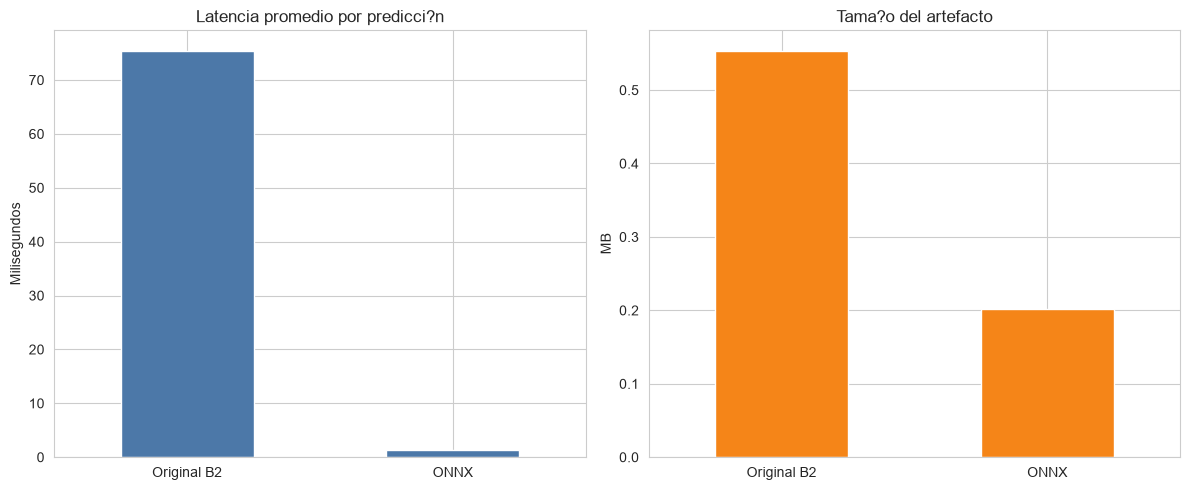

Gr?fico guardado: reports\figures\profiling_comparativo.png


In [8]:
# Graficamos ?nicamente valores que se midieron realmente.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
datos_disponibles = comparacion.loc[comparacion["disponible"]]
datos_disponibles.plot(
    x="modelo", y="latencia_promedio_ms", kind="bar", ax=axes[0],
    color="#4C78A8", legend=False,
)
axes[0].set_title("Latencia promedio por predicci?n")
axes[0].set_ylabel("Milisegundos")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)
datos_disponibles.plot(
    x="modelo", y="tamano_MB", kind="bar", ax=axes[1],
    color="#F58518", legend=False,
)
axes[1].set_title("Tama?o del artefacto")
axes[1].set_ylabel("MB")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
profiling_figure = FIGURES_DIR / "profiling_comparativo.png"
fig.savefig(profiling_figure, dpi=150, bbox_inches="tight")
plt.show()
print("Gr?fico guardado:", profiling_figure.relative_to(PROJECT_ROOT))

## Green AI: sostenibilidad energ?tica

**Green AI** estudia c?mo desarrollar y usar sistemas de inteligencia artificial considerando su consumo de recursos y sus impactos ambientales. Importa porque la inferencia repetida, el almacenamiento y la operaci?n de infraestructura tienen costos; optimizar solo la exactitud puede ignorarlos.

Usaremos las relaciones:

- **Energ?a (kWh) = potencia (kW) ? tiempo (h)**
- **Huella (kg CO?e) = energ?a (kWh) ? factor de emisi?n (kg CO?e/kWh)**

Para el ejercicio configuramos **0.4 kg CO?/kWh** como factor did?ctico para Ecuador. No es una verificaci?n de la intensidad actual de la red: el factor cambia con per?odo, regi?n y fuente. La medici?n directa requerir?a registrar la energ?a real del equipo.

## Estrategias de Green AI

| Estrategia | Impacto potencial | Trade-off o precauci?n |
|---|---|---|
| Modelo m?s ligero | Menos c?mputo, memoria y transferencia | Verificar desempe?o y adecuaci?n al problema |
| Cuantizaci?n | Menor tama?o y operaciones de menor precisi?n | Puede afectar precisi?n; medir en el hardware destino |
| ONNX Runtime | Interoperabilidad y runtime optimizado | La conversi?n no garantiza menor energ?a ni menor latencia |
| Inferencia por lotes | Amortiza el costo de solicitudes y puede aumentar throughput | Esperar a reunir el lote puede subir latencia |
| Hardware eficiente | M?s predicciones por unidad de energ?a | Considerar fabricaci?n, utilizaci?n y disponibilidad |
| Cach? de predicciones | Evita repetir inferencias id?nticas | Requiere invalidaci?n correcta y uso adicional de memoria |

El impacto real depende de carga, infraestructura y patr?n de uso. Hay que medir el sistema completo antes de afirmar que una t?cnica reduce emisiones.

In [9]:
def estimar_huella(latencia_ms, potencia_kW=0.1, factor_emision=0.4, n_inferencias=1_000_000):
    """Estima energ?a por inferencia y CO2e anual con potencia y uso supuestos."""
    if not np.isfinite(latencia_ms) or latencia_ms < 0:
        raise ValueError("latencia_ms debe ser un valor finito no negativo.")
    if not np.isfinite(potencia_kW) or potencia_kW < 0:
        raise ValueError("potencia_kW debe ser un valor finito no negativo.")
    if not np.isfinite(factor_emision) or factor_emision < 0:
        raise ValueError("factor_emision debe ser un valor finito no negativo.")
    if n_inferencias < 0:
        raise ValueError("n_inferencias debe ser no negativo.")

    # Convertimos milisegundos a horas; potencia ? tiempo produce kWh por llamada.
    tiempo_horas = float(latencia_ms) / 3_600_000
    energia_por_inferencia = float(potencia_kW) * tiempo_horas
    huella_anual = energia_por_inferencia * int(n_inferencias) * float(factor_emision)
    return energia_por_inferencia, huella_anual


# Estos valores son estimaciones, no una lectura de potencia del equipo.
POTENCIA_SUPUESTA_KW = 0.1
FACTOR_EMISION_ECUADOR = 0.4
INFERENCIAS_ANUALES = 1_000_000
estimacion_original = estimar_huella(
    latencia_original["promedio"], POTENCIA_SUPUESTA_KW,
    FACTOR_EMISION_ECUADOR, INFERENCIAS_ANUALES,
)
print(
    f"Original: {estimacion_original[0]:.10g} kWh/inferencia; "
    f"{estimacion_original[1]:.6f} kg CO2e/a?o"
)
if onnx_available and ONNX_RUNTIME_AVAILABLE:
    estimacion_onnx = estimar_huella(
        latencia_onnx["promedio"], POTENCIA_SUPUESTA_KW,
        FACTOR_EMISION_ECUADOR, INFERENCIAS_ANUALES,
    )
    ahorro_relativo = (
        100 * (estimacion_original[1] - estimacion_onnx[1]) / estimacion_original[1]
        if estimacion_original[1] > 0 else float("nan")
    )
    print(
        f"ONNX: {estimacion_onnx[0]:.10g} kWh/inferencia; "
        f"{estimacion_onnx[1]:.6f} kg CO2e/a?o"
    )
    print(f"Ahorro estimado de huella frente al original: {ahorro_relativo:.2f}%")
else:
    estimacion_onnx = (float("nan"), float("nan"))
    print("Ahorro ONNX no calculado porque ONNX Runtime no est? disponible.")
print(
    "Supuestos: potencia constante de 0.1 kW, factor de 0.4 kg CO2e/kWh, "
    "1,000,000 inferencias/a?o. No es una medici?n de energ?a."
)

Original: 2.095054194e-06 kWh/inferencia; 0.838022 kg CO2e/a?o
ONNX: 3.939494444e-08 kWh/inferencia; 0.015758 kg CO2e/a?o
Ahorro estimado de huella frente al original: 98.12%
Supuestos: potencia constante de 0.1 kW, factor de 0.4 kg CO2e/kWh, 1,000,000 inferencias/a?o. No es una medici?n de energ?a.


## Interpretaci?n de resultados

**?Cu?nta energ?a ahorra ONNX? ?Cu?nta huella de carbono se reduce? ?Vale la pena el cambio?**

Usa las cifras solo bajo los supuestos declarados de potencia, latencia y volumen anual. Una reducci?n de latencia puede reducir la energ?a estimada si la potencia se mantiene fija, pero el runtime tambi?n puede consumir potencia diferente. Considera tama?o, confiabilidad, calidad y costo de mantenimiento: una conversi?n no es autom?ticamente una mejora sostenible.

In [10]:
# Si ONNX no se midi?, sus valores quedan vac?os en el reporte.
green_ai = pd.DataFrame([
    {
        "modelo": modelo_nombre,
        "energia_por_inferencia_kWh": estimacion_original[0],
        "huella_anual_kgCO2": estimacion_original[1],
    },
    {
        "modelo": "ONNX",
        "energia_por_inferencia_kWh": estimacion_onnx[0],
        "huella_anual_kgCO2": estimacion_onnx[1],
    },
])
green_ai_path = REPORTS_DIR / "green_ai.csv"
green_ai.to_csv(green_ai_path, index=False)
display(green_ai)
print("Reporte Green AI guardado:", green_ai_path.relative_to(PROJECT_ROOT))

,modelo,energia_por_inferencia_kWh,huella_anual_kgCO2
0,Original B2,2.095054e-06,0.838022
1,ONNX,3.939494e-08,0.015758


Reporte Green AI guardado: reports\green_ai.csv


## Gr?fico de huella de carbono

Este gr?fico compara la huella anual **estimada** para el mismo volumen hipot?tico de inferencias y la potencia configurada. No es una medici?n de emisiones reales. Si cambia el n?mero de solicitudes o el factor de emisi?n, tambi?n cambia el resultado.

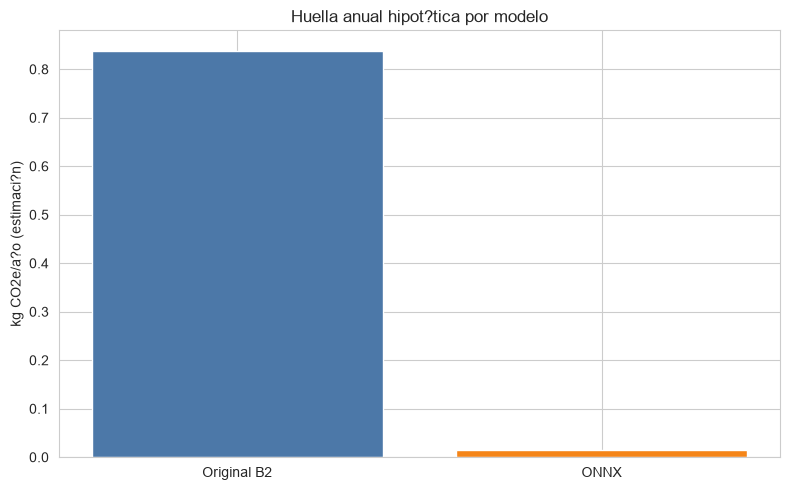

Gr?fico Green AI guardado: reports\figures\green_ai.png


In [11]:
# Mostramos solo los runtimes con una estimaci?n disponible.
fig, ax = plt.subplots(figsize=(8, 5))
green_ai_disponible = green_ai.dropna(subset=["huella_anual_kgCO2"])
ax.bar(
    green_ai_disponible["modelo"],
    green_ai_disponible["huella_anual_kgCO2"],
    color=["#4C78A8", "#F58518"][:len(green_ai_disponible)],
)
ax.set_title("Huella anual hipot?tica por modelo")
ax.set_ylabel("kg CO2e/a?o (estimaci?n)")
ax.set_xlabel("")
plt.tight_layout()
green_ai_figure = FIGURES_DIR / "green_ai.png"
fig.savefig(green_ai_figure, dpi=150, bbox_inches="tight")
plt.show()
print("Gr?fico Green AI guardado:", green_ai_figure.relative_to(PROJECT_ROOT))

## Cierre del Bloque 3

**El Bloque 3 respondi?: ?c?mo llevo mi modelo a producci?n de forma sostenible?**

| Aprendizaje | Aplicaci?n |
|---|---|
| Relevancia | Justificar para qui?n y para qu? se construye el sistema |
| MLOps | Versionar, reproducir y monitorear modelos |
| Docker | Empaquetar una ejecuci?n consistente |
| Profiling | Medir latencia y recursos antes de optimizar |
| Green AI | Evaluar el consumo y explicar los supuestos de impacto |

## Cierre del curso completo

| Bloque | Pregunta | Habilidades |
|---|---|---|
| B1 | ?Funciona? | Datos, preprocesamiento, modelos y an?lisis exploratorio |
| B2 | ?Vale la pena? | M?tricas, costos, umbrales y optimizaci?n |
| B3 | ?C?mo lo despliego? | RL, APIs, Docker, profiling y Green AI |

Durante el curso practicamos pipelines, evaluaci?n, optimizaci?n, aprendizaje por refuerzo, APIs, Docker, profiling y Green AI. El siguiente paso es integrar estos aprendizajes en una entrega evaluable.

**Lo que sigue: examen final y proyecto integrador.**

In [12]:
# Mensaje final con las rutas de los reportes creados.
print("Clase 16 completada. Curso finalizado. Revisa reports/profiling_comparativo.csv, reports/green_ai.csv y reports/figures/")

Clase 16 completada. Curso finalizado. Revisa reports/profiling_comparativo.csv, reports/green_ai.csv y reports/figures/
